<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/6.%20Pilot%20Run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Noise–Signal Trade-off Pilot

Predict-then-optimize fails in two opposite ways in the replication. Least squares fitted per ETF on about 8 monthly rows gives noisy forecasts, and the optimizer trades on the noise. A pooled, shrunk model stops the trading but carries little information. This pilot asks whether one quantity, **data per effective degree of freedom**, places both failures and the models between them on a single axis.

Eighteen forecasters are built by changing one factor at a time:

| Family | Model | Varied | Held fixed |
|---|---|---|---|
| Window | Pooled ridge, penalty 1 (close to least squares) | Training window: 8, 12, 24, 36, 60 months, expanding | Features, penalty |
| Penalty | Pooled ridge | Penalty: 1, 10, 100, 10³, 10⁴, 10⁵ | 36-month window, features |
| Per-ETF | Least squares, one model per ETF | Training window: 8, 12, 24, 36, 60 months, expanding | Features |

The 8-month per-ETF model is Per-ETF PTO from the replication. Every model trains on month-end rows, one per ETF and month, so the rows are non-overlapping and the data count is exact. For each forecaster the pilot measures forecast noise, spread ratio, ranking skill (IC), and the turnover and net Sharpe ratio of the resulting portfolio. Only ETF_A and holding months 2015-01 to 2019-12 are used.

**Data per effective degree of freedom.** For one model, the number of training rows divided by its effective degrees of freedom: 1 + Σ sⱼ² / (sⱼ² + α) for pooled ridge, where sⱼ are the singular values of the centered feature matrix and α the penalty, and the number of coefficients (8) for per-ETF least squares.

**Criteria, fixed before the run.** Across the 18 forecasters, with x = log(data per degree of freedom):

1. **Noise is ordered:** the rank correlation between x and forecast noise is −0.8 or lower.
2. **One axis:** x alone explains at least 70% of the variance of log noise, and adding a dummy for each family raises that share by less than 0.10.
3. **Turnover is ordered:** the rank correlation between x and turnover is −0.7 or lower.

If all three pass, data per effective degree of freedom is the axis of the trade-off map. If 1 passes and 2 fails, the families sit on separate curves and the report names the factor that matters beyond the data count. Ranking skill and Sharpe ratio are reported without a criterion.

**Inputs:** Daily Prices, Monthly Data, Daily Features (`data/processed`)

**Outputs** (`data/reports`):

| File | Contents |
|---|---|
| Noise-Signal Pilot.csv | Data per degree of freedom, noise, spread ratio, IC, turnover and Sharpe ratio of every forecaster |
| Noise-Signal Pilot Criteria.csv | The three criteria |
| Noise-Signal Pilot Follow-up.csv | The one-axis test repeated in the follow-up checks |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: 5cc37cb, Rename 5. Per-ETF PTO Replication Run (WBS: 3.4).ipynb to 5. Per-ETF PTO Replication Run (WBS: 3.6).ipynb (2026-11-10 22:59)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src import backtest, cleaning, config, covariance, forecast

# Reload after a fresh clone
for module in (config, cleaning, covariance, backtest, forecast):
    importlib.reload(module)

# Data folder paths, universe and selection period
DIRS = config.data_dirs()
pd.set_option("display.width", 170)
UNIVERSE, TICKERS = "ETF_A", config.ETF_A
FIRST, LAST = config.SELECTION_PERIOD

## 2. Data and decision dates

Decision dates are the month-ends whose holding month falls in the selection period. Covariances are built for those dates, because the saved covariances cover only the test period.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
table = pd.read_parquet(proc / config.FILES["daily_table"])

# Month-end rows of ETF_A with a known target date
rows_me = table[(table["universe"] == UNIVERSE) & table["month_end"]].sort_values(["date", "ticker"])
dates = pd.DatetimeIndex([d for d in rows_me["date"].unique()
                          if FIRST <= str(d.to_period("M") + 1) <= LAST])

# Holding-month returns and sample covariances
returns = panel[panel["universe"] == UNIVERSE].pivot(index="date", columns="ticker", values="next_return").loc[dates, TICKERS]
cov = backtest.covariance_lookup(covariance.build_covariances(clean, dates), UNIVERSE, "sample")
assert len(dates) == 60 and returns.notna().all().all()

## 3. Forecasters

A training set holds the month-end rows of the last W months whose target is known on the decision date, or all such rows for the expanding window. Pooled ridge uses the replication's design (standardized features plus a 0/1 column per ETF) and solver, checked against them on one date. Per-ETF least squares follows Per-ETF PTO.

In [4]:
WINDOWS = (8, 12, 24, 36, 60, None)
PENALTIES = (1.0, 10.0, 100.0, 1e3, 1e4, 1e5)
BASE_PENALTY, PENALTY_WINDOW = 1.0, 36


def window_label(w):
    """Window as text: months, or expanding."""
    return "expanding" if w is None else f"{w}m"


# One row per forecaster: family, window, penalty and label
SPECS = ([("Window", w, BASE_PENALTY) for w in WINDOWS]
         + [("Penalty", PENALTY_WINDOW, a) for a in PENALTIES]
         + [("Per-ETF", w, None) for w in WINDOWS])
specs = pd.DataFrame(SPECS, columns=["family", "window", "penalty"])
specs["window_label"] = [window_label(w) for _, w, _ in SPECS]
specs["label"] = [f"{f}, {window_label(w)}" + ("" if a is None else f", α={a:g}") for f, w, a in SPECS]


# Month-end features and targets as months x ETFs arrays
wide = rows_me.pivot(index="date", columns="ticker")
MONTHS = wide.index
F = np.stack([wide[c][TICKERS].to_numpy(float) for c in config.FEATURES], axis=-1)
Y = wide["fwd_return"][TICKERS].to_numpy(float)
LABEL = wide["label_date"][TICKERS].max(axis=1).to_numpy()


def training_months(date, window):
    """Indices of the last `window` months whose target is known on `date` (all of them if window is None)."""
    known = np.flatnonzero((MONTHS < date) & (LABEL <= date))
    return known if window is None else known[-window:]


def pooled_ridge(idx, k, alphas):
    """Pooled ridge forecasts for month k from months idx, and each fit's effective degrees of freedom."""
    x = F[idx].reshape(-1, F.shape[2])
    center, scale = x.mean(axis=0), x.std(axis=0)
    scale[scale == 0] = 1.0
    eye = np.tile(np.eye(len(TICKERS)), (len(idx), 1))
    x = np.hstack([(x - center) / scale, eye])
    x_test = np.hstack([(F[k] - center) / scale, np.eye(len(TICKERS))])
    out = {}
    s = np.linalg.svd(x - x.mean(axis=0), compute_uv=False)
    for a, (b0, beta) in zip(alphas, forecast.ridge_fit(x, Y[idx].ravel(), alphas)):
        out[("Pooled", a)] = (b0 + x_test @ beta, 1 + float(np.sum(s ** 2 / (s ** 2 + a))))
    return out


def per_etf_ols(idx, k):
    """Least-squares forecast of each ETF for month k from its own rows in months idx."""
    pred = np.empty(len(TICKERS))
    for i in range(len(TICKERS)):
        x = np.column_stack([np.ones(len(idx)), F[idx, i]])
        beta, *_ = np.linalg.lstsq(x, Y[idx, i], rcond=None)
        pred[i] = beta[0] + F[k, i] @ beta[1:]
    return pred, 1 + len(config.FEATURES)


def forecast_all(idx, k, alphas):
    """Forecasts and degrees of freedom of every forecaster that shares the training months idx."""
    out = pooled_ridge(idx, k, alphas)
    out["Per-ETF"] = per_etf_ols(idx, k)
    return out


# Same forecasts as the replication's design and solver, checked on one date
k, idx = MONTHS.get_loc(dates[30]), training_months(dates[30], 36)
train = rows_me[rows_me["date"].isin(MONTHS[idx])]
test = rows_me[rows_me["date"] == dates[30]]
x, c, sc = forecast._design(train, TICKERS)
b0, beta = forecast.ridge_fit(x, train["fwd_return"].to_numpy(), [10.0])[0]
reference = pd.Series(b0 + forecast._design(test, TICKERS, c, sc)[0] @ beta,
                      index=test["ticker"].to_numpy()).reindex(TICKERS).to_numpy()
assert np.allclose(pooled_ridge(idx, k, [10.0])[("Pooled", 10.0)][0], reference)
assert (MONTHS[idx] < dates[30]).all() and (LABEL[idx] <= dates[30]).all()

## 4. Forecasts and forecast noise

At each decision date, every forecaster is fitted once on its training set and then 100 more times on block-resampled copies of it. Months are resampled in blocks of 3, keeping all ETFs of a month together. Forecast noise is the standard deviation of an ETF's 100 resampled forecasts, averaged over ETFs and months. Forecasters with the same window share the same resamples.

In [5]:
def block_index(n, block, rng):
    """Positions of one circular block resample of n months."""
    starts = rng.integers(0, n, int(np.ceil(n / block)))
    return (np.concatenate([np.arange(s, s + block) for s in starts]) % n)[:n]


def spec_key(row):
    """Key of a forecaster in the output of forecast_all."""
    return "Per-ETF" if row["family"] == "Per-ETF" else ("Pooled", row["penalty"])


# Point forecasts, degrees of freedom and bootstrap noise for every forecaster and date
rng = np.random.default_rng(0)
REFITS, BLOCK = config.BOOTSTRAP_REFITS, config.BOOTSTRAP_BLOCK_MONTHS
point, noise_rows = [], []
for w in WINDOWS:
    members = specs[specs["window_label"] == window_label(w)]
    alphas = sorted(members["penalty"].dropna().unique())
    for d in dates:
        k, idx = MONTHS.get_loc(d), training_months(d, w)
        fits = forecast_all(idx, k, alphas)
        draws = [forecast_all(idx[block_index(len(idx), BLOCK, rng)], k, alphas) for _ in range(REFITS)]
        for i, row in members.iterrows():
            key = spec_key(row)
            pred, df = fits[key]
            boot = np.array([dr[key][0] for dr in draws])
            n = len(idx) * (1 if row["family"] == "Per-ETF" else len(TICKERS))
            point += [{"spec": i, "date": d, "ticker": t, "forecast": pred[j]} for j, t in enumerate(TICKERS)]
            noise_rows.append({"spec": i, "date": d, "rows": n, "df": df, "noise": boot.std(axis=0, ddof=1).mean()})

point, noise = pd.DataFrame(point), pd.DataFrame(noise_rows)
assert np.isfinite(point["forecast"]).all() and len(point) == len(specs) * len(dates) * len(TICKERS)

## 5. Portfolios

Each forecaster's forecasts go into the replication's optimizer at λ = 10, with κ = 0.005, the 0.5% fee, the sample covariance and a start from equal weights. 1/N and minimum variance run on the same months.

In [6]:
LAM = 10


def mean_and_nw_t(x, lags=3):
    """Mean of x and its Newey-West t-statistic."""
    x = np.asarray(x, float)
    e = x - x.mean()
    n = len(x)
    var = e @ e / n + 2 * sum((1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / n for k in range(1, lags + 1))
    return x.mean(), x.mean() / np.sqrt(var / n)


# Forecast quality and portfolio of every forecaster
results = []
for i, row in specs.iterrows():
    f = point[point["spec"] == i].pivot(index="date", columns="ticker", values="forecast").loc[dates, TICKERS]
    ic = [spearmanr(f.loc[d], returns.loc[d])[0] for d in dates]
    ic_mean, ic_t = mean_and_nw_t(ic)
    months, _ = backtest.run(backtest.mean_variance(f, cov, LAM), returns)
    m = backtest.metrics(months)
    nz = noise[noise["spec"] == i]
    results.append({**row.to_dict(), "rows": nz["rows"].mean(), "df": nz["df"].mean(),
                    "data_per_df": (nz["rows"] / nz["df"]).mean(), "noise": nz["noise"].mean(),
                    "spread_ratio": f.std(axis=1).mean() / returns.std(axis=1).mean(),
                    "ic": ic_mean, "ic_t": ic_t, "turnover": m["turnover"], "sharpe": m["sharpe"]})
results = pd.DataFrame(results)

# References without forecasts
refs = {"1/N": backtest.metrics(backtest.run(backtest.equal_weight(len(TICKERS)), returns)[0]),
        "Minimum variance": backtest.metrics(backtest.run(backtest.minimum_variance(cov), returns)[0])}
refs = pd.DataFrame(refs).T[["sharpe", "turnover"]]

cols = ["label", "rows", "df", "data_per_df", "noise", "spread_ratio", "ic", "ic_t", "turnover", "sharpe"]
results.sort_values("data_per_df")[cols].round(3)

,label,rows,df,data_per_df,noise,spread_ratio,ic,ic_t,turnover,sharpe
12,"Per-ETF, 8m",8.000,8.000,1.000,0.226,65.846,0.024,0.510,0.819,-0.576
13,"Per-ETF, 12m",12.000,8.000,1.500,1.628,2.259,0.050,0.977,0.739,0.022
14,"Per-ETF, 24m",24.000,8.000,3.000,0.036,1.111,0.063,1.211,0.618,0.159
15,"Per-ETF, 36m",36.000,8.000,4.500,0.021,0.787,0.087,1.657,0.491,0.314
0,"Window, 8m, α=1",64.000,13.493,4.744,0.022,0.787,0.023,0.485,0.400,-0.287
1,"Window, 12m, α=1",96.000,14.018,6.849,0.018,0.624,0.030,0.529,0.299,0.119
16,"Per-ETF, 60m",59.967,8.000,7.496,0.014,0.545,0.167,2.210,0.325,0.482
17,"Per-ETF, expanding",88.167,8.000,11.021,0.011,0.518,0.145,2.111,0.264,0.664
2,"Window, 24m, α=1",192.000,14.524,13.220,0.013,0.423,0.047,0.931,0.122,0.760
3,"Window, 36m, α=1",288.000,14.683,19.615,0.011,0.365,0.158,3.118,0.077,0.939


In [7]:
refs.round(3)

,sharpe,turnover
1/N,0.793,0.008
Minimum variance,1.156,0.037


## 6. The trade-off on one axis

Each point is one forecaster; the x-axis is data per effective degree of freedom on a log scale. The last panel shows the trade-off directly: forecast noise against ranking skill.

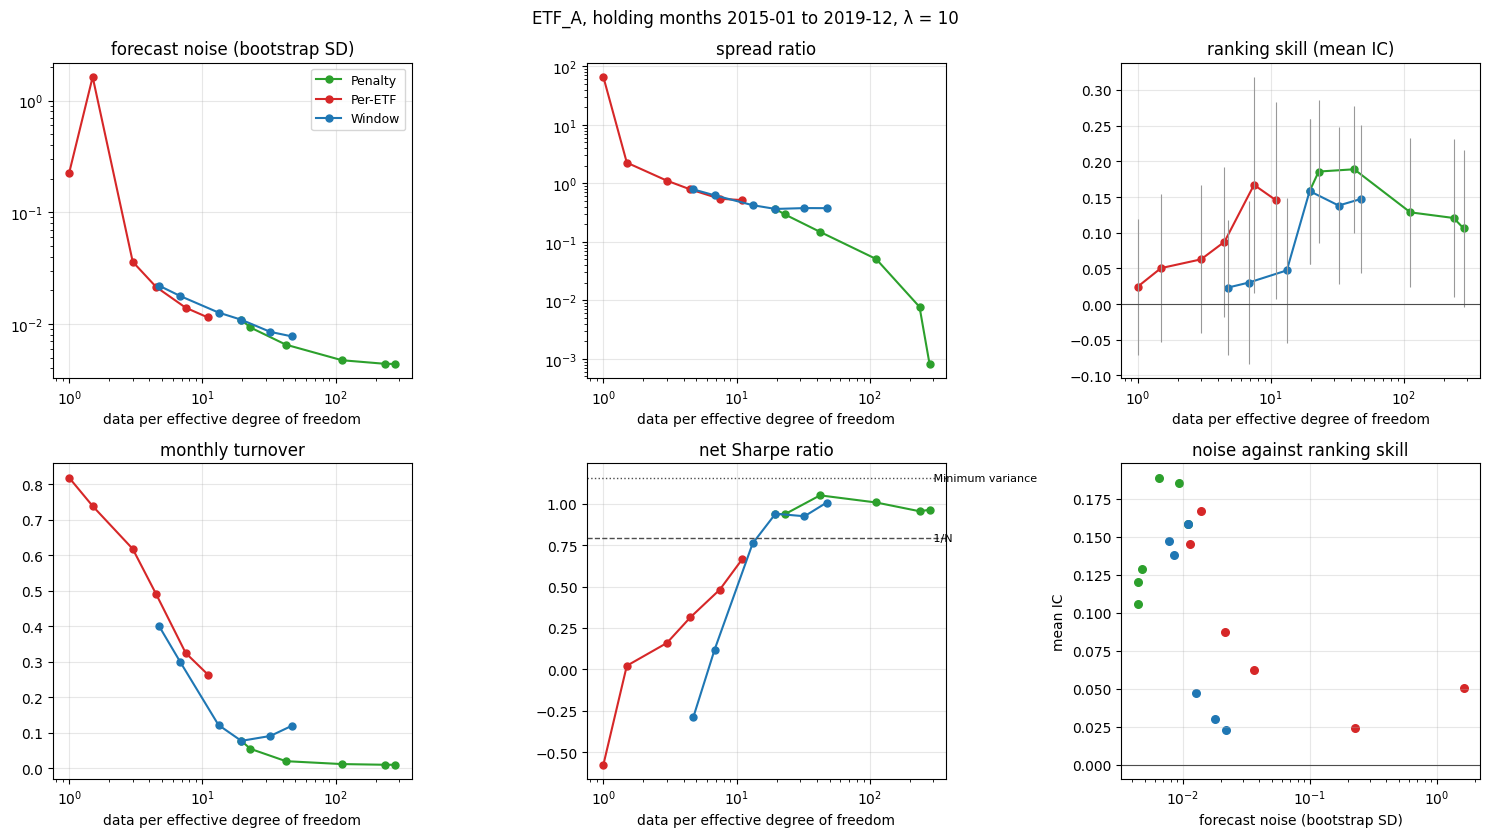

In [8]:
# Six measures against data per degree of freedom
colors = {"Window": "tab:blue", "Penalty": "tab:green", "Per-ETF": "tab:red"}
panels = [("noise", "forecast noise (bootstrap SD)", True), ("spread_ratio", "spread ratio", True),
          ("ic", "ranking skill (mean IC)", False), ("turnover", "monthly turnover", False),
          ("sharpe", "net Sharpe ratio", False)]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (col, name, logy) in zip(axes.flat, panels):
    for fam, g in results.groupby("family"):
        g = g.sort_values("data_per_df")
        ax.plot(g["data_per_df"], g[col], "o-", color=colors[fam], label=fam, ms=5)
    if col == "ic":
        se = results["ic"] / results["ic_t"]
        ax.errorbar(results["data_per_df"], results["ic"], yerr=2 * se, fmt="none", ecolor="0.6", lw=0.8)
        ax.axhline(0, color="0.3", lw=0.8)
    if col == "sharpe":
        for ref, ls in (("1/N", "--"), ("Minimum variance", ":")):
            ax.axhline(refs.loc[ref, "sharpe"], color="0.3", ls=ls, lw=1)
            ax.text(results["data_per_df"].max(), refs.loc[ref, "sharpe"], f" {ref}", va="center", fontsize=8)
    ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("data per effective degree of freedom")
    ax.set_title(name)
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=9)

ax = axes[1, 2]
for fam, g in results.groupby("family"):
    ax.scatter(g["noise"], g["ic"], color=colors[fam], label=fam, s=30)
ax.set_xscale("log")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("forecast noise (bootstrap SD)")
ax.set_ylabel("mean IC")
ax.set_title("noise against ranking skill")
ax.grid(alpha=0.3)
fig.suptitle("ETF_A, holding months 2015-01 to 2019-12, λ = 10")
fig.tight_layout()
plt.show()

## 7. Criteria

In [9]:
# Rank correlations and the share of log noise explained, with and without family dummies
x = np.log(results["data_per_df"].to_numpy())
y = np.log(results["noise"].to_numpy())


def r_squared(design, y):
    """Share of the variance of y explained by a least-squares fit on `design`."""
    beta, *_ = np.linalg.lstsq(design, y, rcond=None)
    return 1 - np.sum((y - design @ beta) ** 2) / np.sum((y - y.mean()) ** 2)


one = np.column_stack([np.ones_like(x), x])
dummies = pd.get_dummies(results["family"], drop_first=True).to_numpy(float)
r2_axis, r2_family = r_squared(one, y), r_squared(np.column_stack([one, dummies]), y)
rho_noise = spearmanr(x, results["noise"])[0]
rho_turnover = spearmanr(x, results["turnover"])[0]

criteria = pd.DataFrame([
    {"criterion": "1. Noise is ordered", "status": "PASS" if rho_noise <= -0.8 else "FAIL",
     "detail": f"rank correlation {rho_noise:.2f}"},
    {"criterion": "2. One axis", "status": "PASS" if r2_axis >= 0.7 and r2_family - r2_axis < 0.10 else "FAIL",
     "detail": f"R² {r2_axis:.2f}; with family dummies {r2_family:.2f}"},
    {"criterion": "3. Turnover is ordered", "status": "PASS" if rho_turnover <= -0.7 else "FAIL",
     "detail": f"rank correlation {rho_turnover:.2f}"},
])
criteria

,criterion,status,detail
0,1. Noise is ordered,PASS,rank correlation -0.99
1,2. One axis,FAIL,R² 0.66; with family dummies 0.69
2,3. Turnover is ordered,PASS,rank correlation -0.95


## 8. Follow-up checks

These checks were added after the criteria were evaluated and are not part of them.

**Bootstrap noise near one row per coefficient.** A block resample of 8 or 12 months repeats some months, so it often has fewer distinct rows than the 8 coefficients of a per-ETF model. The refit is then underdetermined, and its spread says more about the resampling than about the forecaster. The one-axis test is repeated without the forecasters below 2 rows per degree of freedom, and with the spread ratio, which needs no resampling.

In [10]:
# One-axis test without the forecasters below 2 rows per degree of freedom, and with the spread ratio
keep = results["data_per_df"] >= 2
follow_up = pd.DataFrame([
    {"test": "noise, at least 2 rows per df", "forecasters": int(keep.sum()),
     "r2_axis": r_squared(one[keep], y[keep]),
     "r2_with_families": r_squared(np.column_stack([one, dummies])[keep], y[keep])},
    {"test": "spread ratio, all forecasters", "forecasters": len(results),
     "r2_axis": r_squared(one, np.log(results["spread_ratio"].to_numpy())),
     "r2_with_families": r_squared(np.column_stack([one, dummies]), np.log(results["spread_ratio"].to_numpy()))},
])
follow_up.round(3)

,test,forecasters,r2_axis,r2_with_families
0,"noise, at least 2 rows per df",16,0.935,0.935
1,"spread ratio, all forecasters",18,0.817,0.832


**Ranking skill and window length.** The window and per-ETF families use the same six windows, but at very different data per degree of freedom. Plotting their IC against the window length shows whether ranking skill follows the data count or the length of history.

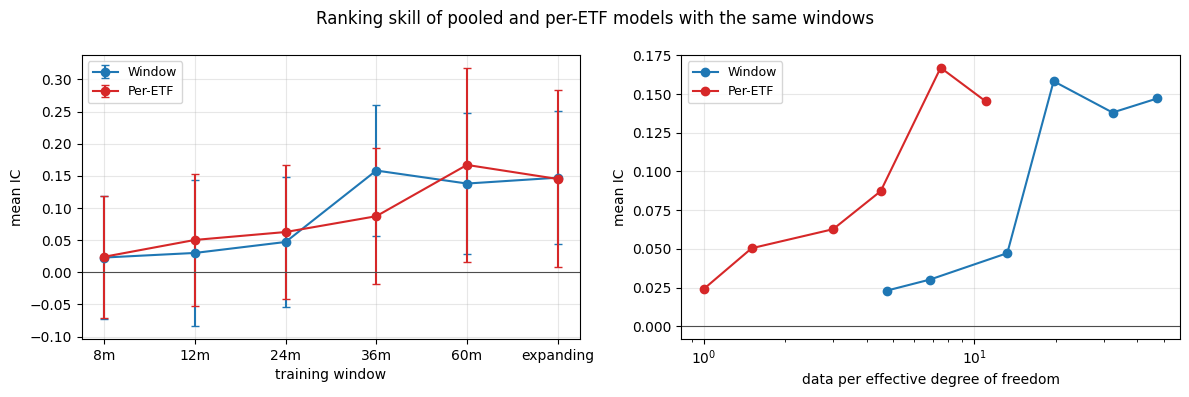

In [11]:
# Mean IC of the two families against the training window
order = [window_label(w) for w in WINDOWS]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for fam in ("Window", "Per-ETF"):
    g = results[results["family"] == fam].set_index("window_label").loc[order]
    se = g["ic"] / g["ic_t"]
    axes[0].errorbar(range(len(order)), g["ic"], yerr=2 * se, marker="o", capsize=3, color=colors[fam], label=fam)
    axes[1].plot(g["data_per_df"], g["ic"], "o-", color=colors[fam], label=fam)
axes[0].set_xticks(range(len(order)), order)
axes[0].set_xlabel("training window")
axes[1].set_xscale("log")
axes[1].set_xlabel("data per effective degree of freedom")
for ax in axes:
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_ylabel("mean IC")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
fig.suptitle("Ranking skill of pooled and per-ETF models with the same windows")
fig.tight_layout()
plt.show()

## 9. Save

In [12]:
results[["family", "label", "window_label", "penalty"] + cols[1:]].to_csv(DIRS["reports"] / "Noise-Signal Pilot.csv", index=False)
criteria.to_csv(DIRS["reports"] / "Noise-Signal Pilot Criteria.csv", index=False)
follow_up.to_csv(DIRS["reports"] / "Noise-Signal Pilot Follow-up.csv", index=False)